# Physics 4C: Constitutive Law P12 without prior

*Note (xkan 1.0 port).* Run top to bottom, this notebook stops short of the exact law in its original output, $0.42 (F_{11} F_{21} + F_{12} F_{22} + F_{13} F_{23})$: the network reaches an RMSE of about 0.06 and finds the linear part $0.42 (F_{12} + F_{21})$. The original output came from cells run out of order. Each released pykan gives the same 0.06 on these data, and a search over eight seeds and three initialisations (pykan's of August 2024 among them) did no better. Physics 4B, which starts from the linear law, comes close.

In [1]:
from constitutive_laws_generator import LinearElasticConstitutiveLaw, NeoHookeanConstitutiveLaw
import torch
import matplotlib.pyplot as plt
import numpy as np
import random
from sympy import symbols, expand
from xkan import KANNetwork, fit, create_dataset_from_data

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.use_deterministic_algorithms(True)
torch.set_default_dtype(torch.float64)

N = 1000
sigma = 0.5 # previously sigma = 0.2

F = torch.eye(3,3)[None,:,:].expand(N,3,3) + (torch.rand(N,3,3)*2-1)*sigma
det = torch.det(F)
F *= (det > 0)[:,None,None]
F_flatten = F.reshape(N, -1)

linear = LinearElasticConstitutiveLaw(young_modulus=1.0, poisson_ratio=0.2)
P_l = linear(F)
P11_l = P_l[:,[0],[0]]
P12_l = P_l[:,[0],[1]]

neo = NeoHookeanConstitutiveLaw(young_modulus=1.0, poisson_ratio=0.2)
P_n = neo(F)
P11_n = P_n[:,[0],[0]]
P12_n = P_n[:,[0],[1]]

# P11
# linear: P11 = 2 * mu * (F11 - 1) + lambda * (F11 + F22 + F33 - 3)
# neohookean: P11 = mu * (F11^2 + F12^2 + F13^2 - 1) + lambda * log(|F|)

# P12
# linear: P12 = mu * (F12 + F21)
# neohookean: P12 = mu * (F11 * F21 + F12 * F22 + F13 * F23)
input_vars = F11, F12, F13, F21, F22, F23, F31, F32, F33 = symbols('F11 F12 F13 F21 F22 F23 F31 F32 F33')
train, test = create_dataset_from_data(F_flatten, P12_n)

In [2]:
# train from scratch without prior knowledge
model2 = KANNetwork([9, [5, 5], 1], base_fun='identity', sparse_init=True, seed=2)
history = fit(model2, train, test, steps=100, lamb=1e-5, lamb_coef=1.0)
print('train RMSE', np.sqrt(history['train/y'][-1]), 'test RMSE', np.sqrt(history['val/y'][-1]))

train RMSE 0.05482417739665169 test RMSE 0.06287476691903217


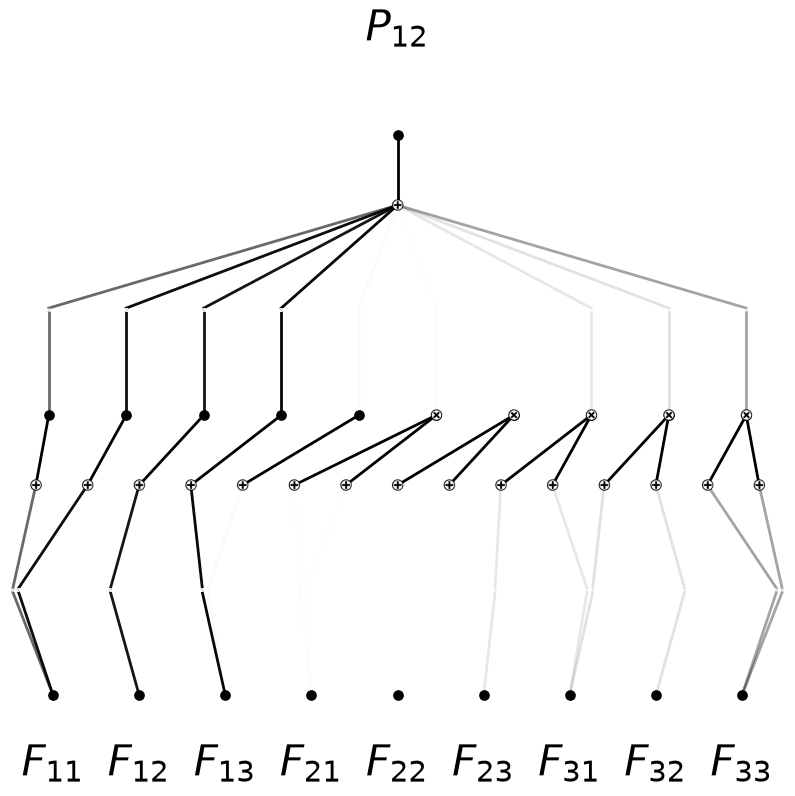

In [3]:
from xkan.viz import plot
model = KANNetwork([9, [5, 5], 1], base_fun='identity', sparse_init=True, seed=2)
plot(model, F_flatten, in_vars=input_vars, scale=1.0, varscale=0.75, out_vars=[r'$P_{12}$']);

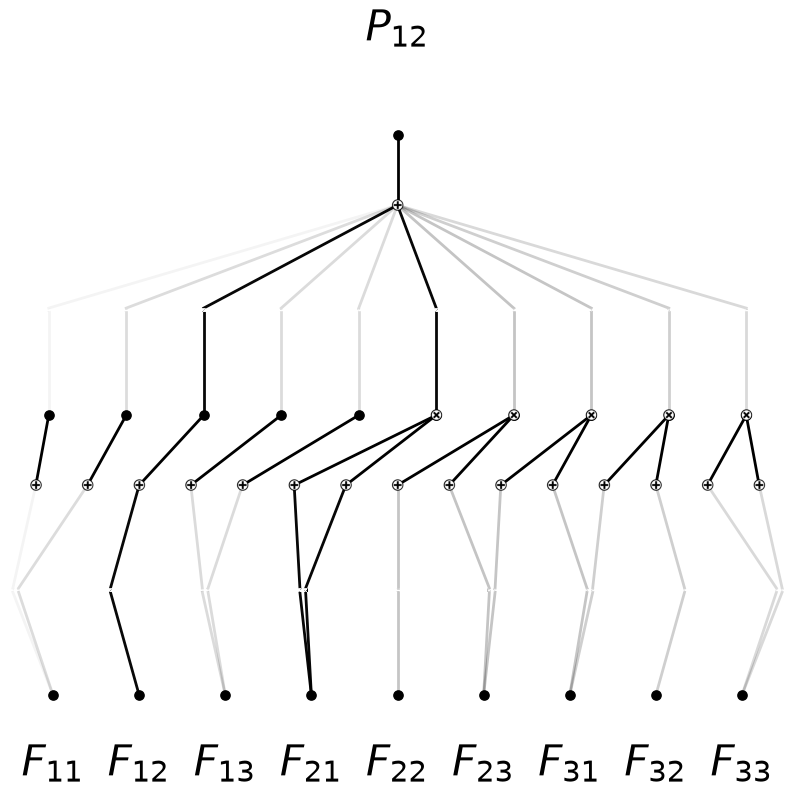

In [4]:
plot(model2, train['x'], in_vars=input_vars, scale=1.0, varscale=0.75, out_vars=[r'$P_{12}$']);

In [5]:
from xkan.interp import prune
model2 = prune(model2, train['x'])

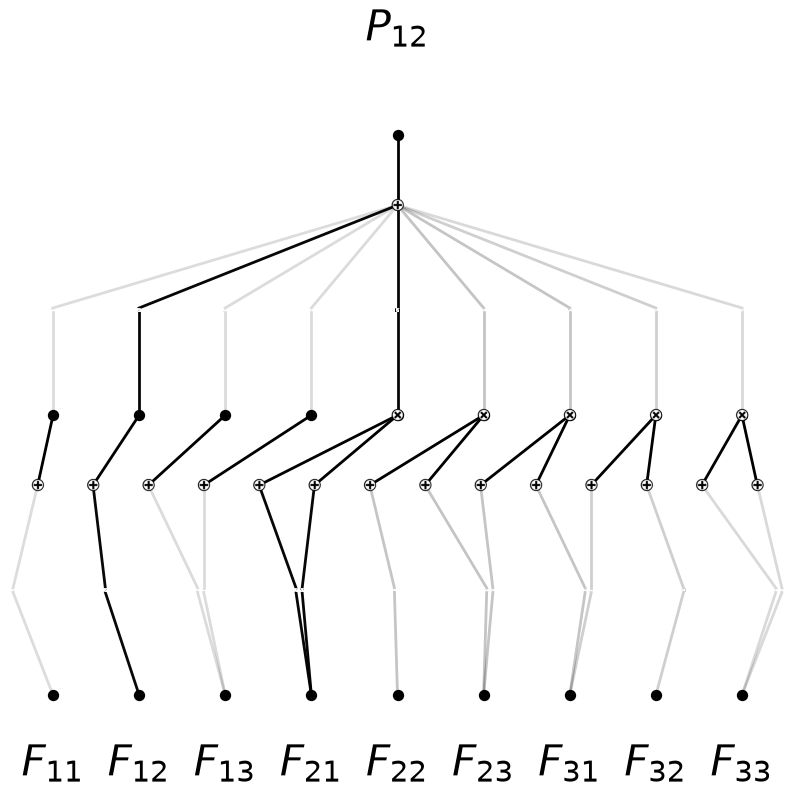

In [6]:
plot(model2, train['x'], in_vars=input_vars, scale=1.0, varscale=0.75, out_vars=[r'$P_{12}$']);

In [7]:
history = fit(model2, train, test, steps=100)
print('train RMSE', np.sqrt(history['train/y'][-1]), 'test RMSE', np.sqrt(history['val/y'][-1]))

train RMSE 0.05428206250180468 test RMSE 0.06422650844511663


In [8]:
from xkan.symbolic import auto_symbolic
auto_symbolic(model2, train['x'])

fixing (0,0,1) with 0
fixing (0,0,2) with 0
fixing (0,0,3) with 0
fixing (0,0,4) with 0
fixing (0,0,5) with 0
fixing (0,0,6) with 0


fixing (0,0,7) with 0
fixing (0,0,8) with 0


fixing (0,0,9) with 0
fixing (0,0,10) with 0
fixing (0,0,11) with 0
fixing (0,0,12) with 0
fixing (0,0,13) with 0
fixing (0,1,0) with 0


fixing (0,1,2) with 0
fixing (0,1,3) with 0


fixing (0,1,4) with 0
fixing (0,1,5) with 0
fixing (0,1,6) with 0
fixing (0,1,7) with 0
fixing (0,1,8) with 0


fixing (0,1,9) with 0


... (49 outputs left out)

fixing (1,6,0) with x, r2=0.022732621612707952, c=1


fixing (1,7,0) with x, r2=0.07807589638748924, c=1


fixing (1,8,0) with x, r2=0.009441521661146455, c=1


{(0, 0, 0): ('x', np.float64(0.6260227799645294), np.int64(1)),
 (0, 1, 1): ('x', np.float64(0.9803838866775385), np.int64(1)),
 (0, 2, 2): ('x', np.float64(0.4102709258643479), np.int64(1)),
 (0, 2, 3): ('sin', np.float64(0.9994535394665442), np.int64(2)),
 (0, 3, 4): ('cos', np.float64(0.986497996114763), np.int64(2)),
 (0, 3, 5): ('x', np.float64(0.03225536589439247), np.int64(1)),
 (0, 4, 6): ('x', np.float64(0.2468457582494557), np.int64(1)),
 (0, 5, 7): ('x', np.float64(0.31995236142362593), np.int64(1)),
 (0, 5, 8): ('x', np.float64(0.7589153488371305), np.int64(1)),
 (0, 6, 9): ('sin', np.float64(0.995237733725032), np.int64(2)),
 (0, 6, 10): ('x', np.float64(0.6917946199195419), np.int64(1)),
 (0, 7, 11): ('x', np.float64(0.7944470393684662), np.int64(1)),
 (0, 8, 12): ('x', np.float64(0.8288785097384535), np.int64(1)),
 (0, 8, 13): ('x', np.float64(0.5537014741519197), np.int64(1)),
 (1, 0, 0): ('x', np.float64(0.008081816526166581), np.int64(1)),
 (1, 1, 0): ('x', np.float64

In [9]:
from xkan.symbolic import fix_symbolic, unfix_symbolic
unfix_symbolic(model2, 1, 1, 0)
fix_symbolic(model2, 1, 1, 0, 'x', train['x'])
unfix_symbolic(model2, 1, 2, 0)
fix_symbolic(model2, 1, 2, 0, 'x', train['x'])

tensor(0.7668)

In [10]:
history = fit(model2, train, test, steps=100)
print('train RMSE', np.sqrt(history['train/y'][-1]), 'test RMSE', np.sqrt(history['val/y'][-1]))

train RMSE 0.059323222338305816 test RMSE 0.06037920126998986


In [11]:
from xkan.symbolic import symbolic_formula
from xkan.utils import ex_round
# expanded before rounding: rounding first can drop a term (a small factor in front of a large inner one)
ex_round(expand(symbolic_formula(model2, var=input_vars)[0][0]), 2)

0.42*F12 - 0.06*F13 + 0.43*F21 - 0.01*F22*F23 + 0.01*F22 + 0.56*F23*sin(0.72*F31 + 4.8) + 0.54*F23 + 0.02*F31*F32 + 0.01*F31 - 0.01*F32 - 0.01*sin(4.22*F13 - 3.05) - 0.14*sin(0.72*F31 + 4.8) - 0.16